# Group 1 analysis

## A. Data source and loading

Data source and setup

The accompanying Excel file, Real estate valuation data set.xlsx, contains the UCI Real Estate Valuation dataset (Yeh, 2018). Place the file in the same folder as Group_1_analysis.ipynb, keep its filename unchanged, and run the notebook



In [45]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd
import statsmodels.api as sm
from scipy.stats import pearsonr, spearmanr

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

Data_URL = (
    "https://archive.ics.uci.edu/static/public/477/"
    "real+estate+valuation+data+set.zip"
)

print("Data URL: " + Data_URL)

df = pd.read_excel("Real estate valuation data set.xlsx")

df.head()

Data URL: https://archive.ics.uci.edu/static/public/477/real+estate+valuation+data+set.zip


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


## B. Data checks and descriptive outputs


In [2]:
print(df.columns.tolist())
print(df.shape)

['No', 'X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']
(414, 8)


In [3]:
#Check duplicated rows.
print("Duplicate rows (excluding ID):", df.drop(columns="No").duplicated().sum())

# Check the range of the two main variables
print(df[[
    "X3 distance to the nearest MRT station",
    "Y house price of unit area"
]].agg(["min", "max"]))

Duplicate rows (excluding ID): 0
     X3 distance to the nearest MRT station  Y house price of unit area
min                                23.38284                         7.6
max                              6488.02100                       117.5


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [5]:
# Select the two variables
distance = df["X3 distance to the nearest MRT station"]
price = df["Y house price of unit area"]

# Descriptive statistics
df[[
    "X3 distance to the nearest MRT station",
    "Y house price of unit area"
]].describe()

,X3 distance to the nearest MRT station,Y house price of unit area
count,414.000000,414.000000
mean,1083.885689,37.980193
std,1262.109595,13.606488
min,23.382840,7.600000
25%,289.324800,27.700000
50%,492.231300,38.450000
75%,1454.279000,46.600000
max,6488.021000,117.500000


In [6]:
print("Number of observations:", len(df))
print("Missing values:")
print(df[[
    "X3 distance to the nearest MRT station",
    "Y house price of unit area"
]].isna().sum())


Number of observations: 414
Missing values:
X3 distance to the nearest MRT station    0
Y house price of unit area                0
dtype: int64


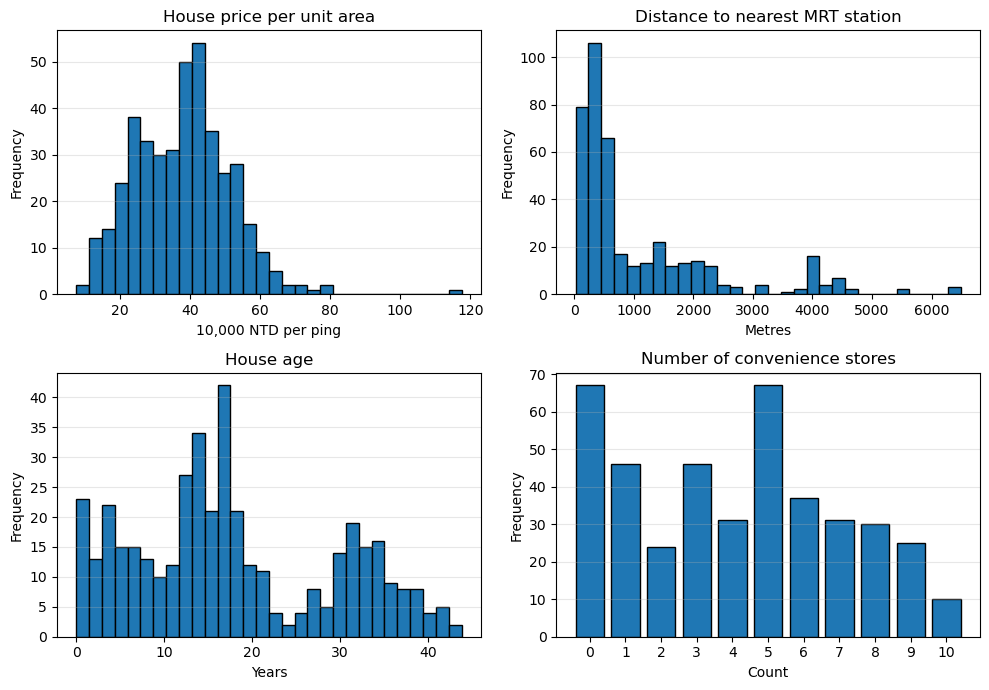

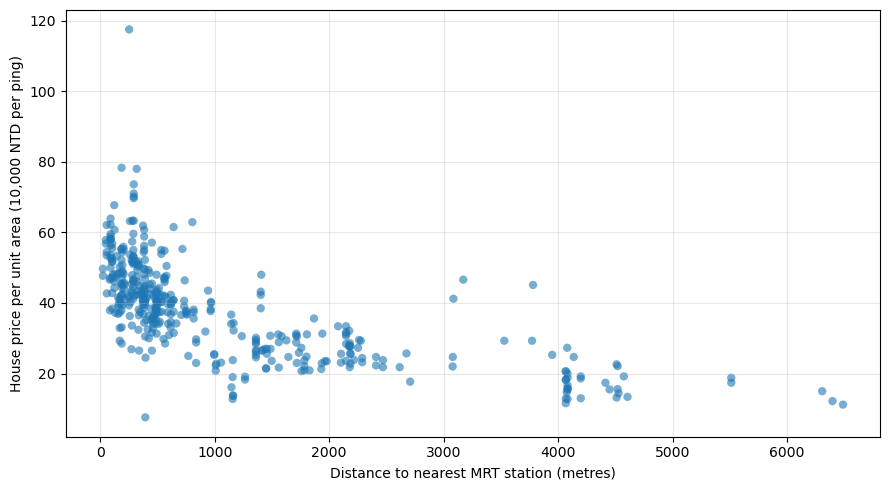

                 Variable            Unit    Mean      SD  Median   Min     Max
House price per unit area 10,000 NTD/ping   37.98   13.61   38.45  7.60  117.50
  Distance to nearest MRT               m 1083.89 1262.11  492.23 23.38 6488.02
                House age           years   17.71   11.39   16.10  0.00   43.80
       Convenience stores           count    4.09    2.95    4.00  0.00   10.00


In [7]:
price_col = "Y house price of unit area"
dist = "X3 distance to the nearest MRT station"
age = "X2 house age"
stores = "X4 number of convenience stores"


#Figure 1: Distributions

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(df[price_col], bins=30, edgecolor="black")
axes[0, 0].set_title("House price per unit area")
axes[0, 0].set_xlabel("10,000 NTD per ping")

axes[0, 1].hist(df[dist], bins=30, edgecolor="black")
axes[0, 1].set_title("Distance to nearest MRT station")
axes[0, 1].set_xlabel("Metres")

axes[1, 0].hist(df[age], bins=30, edgecolor="black")
axes[1, 0].set_title("House age")
axes[1, 0].set_xlabel("Years")

# Discrete variable: bar chart, no gaps between bins
counts = df[stores].value_counts().sort_index()
axes[1, 1].bar(counts.index, counts.values, width=0.8, edgecolor="black")
axes[1, 1].set_title("Number of convenience stores")
axes[1, 1].set_xlabel("Count")
axes[1, 1].set_xticks(range(0, 11))

for ax in axes.flat:
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure1_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 2: Distance vs price scatterplot
plt.figure(figsize=(9, 5))
plt.scatter(df[dist], df[price_col], alpha=0.6, edgecolor="none")
plt.xlabel("Distance to nearest MRT station (metres)")
plt.ylabel("House price per unit area (10,000 NTD per ping)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure2_scatter.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Table 1: descriptive statistics
cols = {
    "Y house price of unit area": ("House price per unit area", "10,000 NTD/ping"),
    "X3 distance to the nearest MRT station": ("Distance to nearest MRT", "m"),
    "X2 house age": ("House age", "years"),
    "X4 number of convenience stores": ("Convenience stores", "count"),
}
table1 = pd.DataFrame({
    "Variable": [v[0] for v in cols.values()],
    "Unit": [v[1] for v in cols.values()],
    "Mean": [df[c].mean() for c in cols],
    "SD": [df[c].std() for c in cols],
    "Median": [df[c].median() for c in cols],
    "Min": [df[c].min() for c in cols],
    "Max": [df[c].max() for c in cols],
}).round(2)

print(table1.to_string(index=False))
table1.to_csv(OUTPUT_DIR / "table1_descriptives.csv", index=False)


## C. Correlation analysis

In [8]:
#Calculate Pearson's correlation coefficient
pearson_r, pearson_p = pearsonr(distance, price)

print("Pearson correlation:", pearson_r)
print("Pearson p-value:", pearson_p)

Pearson correlation: -0.6736128553689181
Pearson p-value: 4.6398250303615055e-56


In [9]:
#Calculate Spearman's rank correlation coefficient.
spearman_r, spearman_p = spearmanr(distance, price)

print("Spearman correlation:", spearman_r)
print("Spearman p-value:", spearman_p)


Spearman correlation: -0.7759483354370685
Spearman p-value: 1.8116573146108762e-84


In [10]:
correlation_results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [pearson_r, spearman_r],
    "P-value": [pearson_p, spearman_p]
})

correlation_results


,Method,Correlation,P-value
0,Pearson,-0.673613,4.639825e-56
1,Spearman,-0.775948,1.811657e-84


In [11]:
# Create a new dataset excluding the extreme price observation.
df_no_outlier = df[
    df["Y house price of unit area"] != 117.5
].copy()

print("Original sample size:", len(df))
print("New sample size:", len(df_no_outlier))


Original sample size: 414
New sample size: 413


In [12]:

#Select variables from the new dataset
distance_new = df_no_outlier[
    "X3 distance to the nearest MRT station"
]

price_new = df_no_outlier[
    "Y house price of unit area"
]

# Recalculate Pearson
pearson_new, pearson_p_new = pearsonr(
    distance_new, price_new
)

# Recalculate Spearman
spearman_new, spearman_p_new = spearmanr(
    distance_new, price_new
)

print("Pearson without outlier:", pearson_new)
print("Pearson p-value:", pearson_p_new)

print("Spearman without outlier:", spearman_new)
print("Spearman p-value:", spearman_p_new)


Pearson without outlier: -0.6940089730153478
Pearson p-value: 1.2810885740469627e-60
Spearman without outlier: -0.7757908059186034
Spearman p-value: 3.262949196341888e-84


In [13]:
correlation_comparison = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Original": [pearson_r, spearman_r],
    "Without 117.5": [pearson_new, spearman_new],
    "Change": [
        pearson_new - pearson_r,
        spearman_new - spearman_r
    ],
    "Original p-value": [pearson_p, spearman_p],
    "New p-value": [pearson_p_new, spearman_p_new]
})

display(correlation_comparison)

,Method,Original,Without 117.5,Change,Original p-value,New p-value
0,Pearson,-0.673613,-0.694009,-0.020396,4.639825e-56,1.281089e-60
1,Spearman,-0.775948,-0.775791,0.000158,1.811657e-84,3.262949e-84


## D. Regression exploration

In [14]:
X_distance = df[["X3 distance to the nearest MRT station"]]

y = df["Y house price of unit area"]
model_simple = sm.OLS(
    y,
    sm.add_constant(X_distance)
)

result_simple = model_simple.fit()

print(result_simple.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.454
Model:                                    OLS   Adj. R-squared:                  0.452
Method:                         Least Squares   F-statistic:                     342.2
Date:                        Tue, 03 Nov 2026   Prob (F-statistic):           4.64e-56
Time:                                14:58:10   Log-Likelihood:                -1542.5
No. Observations:                         414   AIC:                             3089.
Df Residuals:                             412   BIC:                             3097.
Df Model:                                   1                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [15]:
X_multiple = df[[
    "X3 distance to the nearest MRT station",
    "X2 house age",
    "X4 number of convenience stores"
]]

model_multiple = sm.OLS(
    y,
    sm.add_constant(X_multiple)
)

result_multiple = model_multiple.fit()

print(result_multiple.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.541
Model:                                    OLS   Adj. R-squared:                  0.538
Method:                         Least Squares   F-statistic:                     161.1
Date:                        Tue, 03 Nov 2026   Prob (F-statistic):           5.44e-69
Time:                                14:58:10   Log-Likelihood:                -1506.5
No. Observations:                         414   AIC:                             3021.
Df Residuals:                             410   BIC:                             3037.
Df Model:                                   3                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

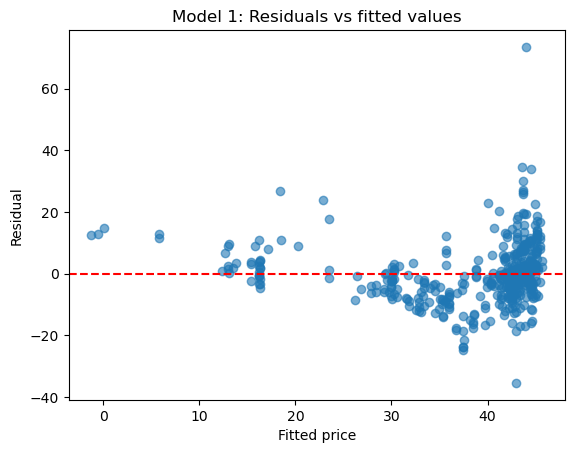

In [16]:
plt.scatter(
    result_simple.fittedvalues,
    result_simple.resid,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Fitted price")
plt.ylabel("Residual")
plt.title("Model 1: Residuals vs fitted values")

plt.show()

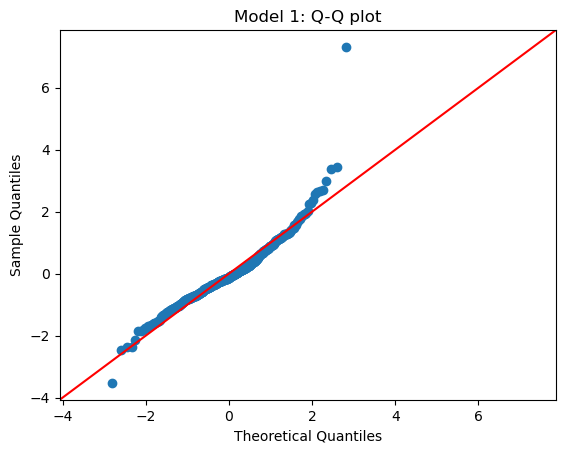

In [17]:
sm.qqplot(
    result_simple.resid,
    fit=True,
    line="45"
)

plt.title("Model 1: Q-Q plot")
plt.show()

In [18]:
diagnostics = df.copy()

diagnostics["fitted_model2"] = result_multiple.fittedvalues
diagnostics["residual_model2"] = result_multiple.resid

largest_errors = (
    diagnostics["residual_model2"]
    .abs()
    .nlargest(5)
    .index
)

diagnostics.loc[
    largest_errors,
    [
        "No",
        "Y house price of unit area",
        "X3 distance to the nearest MRT station",
        "X2 house age",
        "X4 number of convenience stores",
        "fitted_model2",
        "residual_model2"
    ]
]

,No,Y house price of unit area,X3 distance to the nearest MRT station,X2 house age,X4 number of convenience stores,fitted_model2,residual_model2
270,271,117.5,252.5822,10.8,1,40.185213,77.314787
113,114,7.6,393.2606,14.8,6,44.904275,-37.304275
220,221,78.3,186.5101,37.2,9,44.244770,34.055230
312,313,78.0,318.5292,35.4,9,43.989762,34.010238
126,127,62.9,804.6897,38.6,4,34.078291,28.821709


In [19]:
print("whether all distance is bigger than 0：", (distance > 0).all())

whether all distance is bigger than 0： True


In [20]:
df_log_distance = df.copy()

df_log_distance["log_distance"] = np.log(distance)

In [21]:
X_log_distance = df_log_distance[[
    "log_distance",
    "X2 house age",
    "X4 number of convenience stores"
]]

model_log_distance = sm.OLS(
    y,
    sm.add_constant(X_log_distance)
)

result_log_distance = model_log_distance.fit()

print(result_log_distance.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.579
Model:                                    OLS   Adj. R-squared:                  0.576
Method:                         Least Squares   F-statistic:                     187.6
Date:                        Tue, 03 Nov 2026   Prob (F-statistic):           1.43e-76
Time:                                14:58:10   Log-Likelihood:                -1488.8
No. Observations:                         414   AIC:                             2986.
Df Residuals:                             410   BIC:                             3002.
Df Model:                                   3                                         
Covariance Type:                    nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
------------------------------

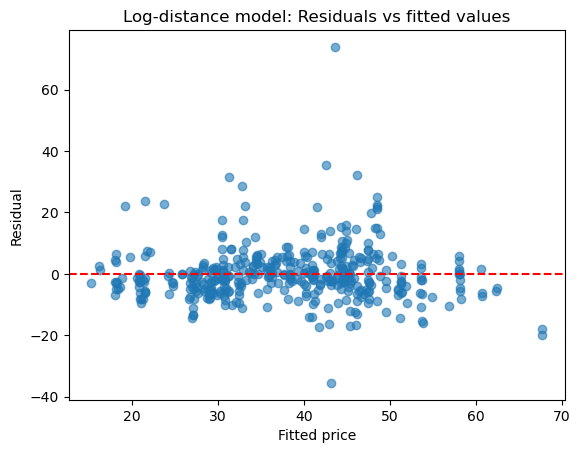

In [22]:
plt.scatter(
    result_log_distance.fittedvalues,
    result_log_distance.resid,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Fitted price")
plt.ylabel("Residual")
plt.title("Log-distance model: Residuals vs fitted values")
plt.show()

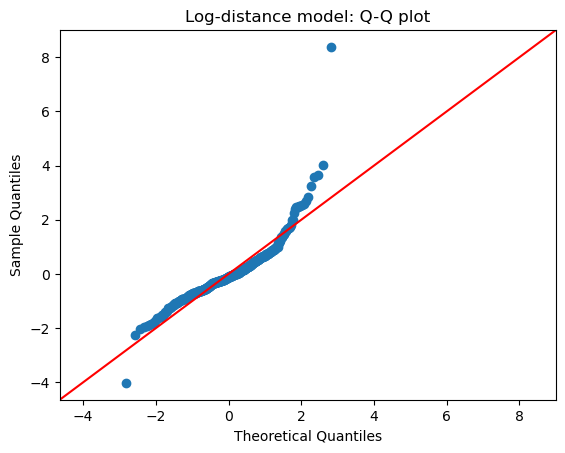

In [23]:
sm.qqplot(
    result_log_distance.resid,
    fit=True,
    line="45"
)

plt.title("Log-distance model: Q-Q plot")
plt.show()

## E. Final log-price models used in the report

In [24]:
print("whether all price bigger than 0：", (y > 0).all())

whether all price bigger than 0： True


In [25]:
log_price = np.log(y)

In [26]:
model_log_price_simple = sm.OLS(
    log_price,
    sm.add_constant(X_distance)
)

result_log_price_simple = model_log_price_simple.fit()

print(result_log_price_simple.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.566
Model:                                    OLS   Adj. R-squared:                  0.565
Method:                         Least Squares   F-statistic:                     537.3
Date:                        Tue, 03 Nov 2026   Prob (F-statistic):           1.09e-76
Time:                                14:58:10   Log-Likelihood:                -26.939
No. Observations:                         414   AIC:                             57.88
Df Residuals:                             412   BIC:                             65.93
Df Model:                                   1                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [27]:
model_log_price = sm.OLS(
    log_price,
    sm.add_constant(X_multiple)
)

result_log_price = model_log_price.fit()

print(result_log_price.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.634
Model:                                    OLS   Adj. R-squared:                  0.631
Method:                         Least Squares   F-statistic:                     236.4
Date:                        Tue, 03 Nov 2026   Prob (F-statistic):           5.05e-89
Time:                                14:58:10   Log-Likelihood:                 8.1469
No. Observations:                         414   AIC:                            -8.294
Df Residuals:                             410   BIC:                             7.810
Df Model:                                   3                                         
Covariance Type:                    nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [28]:
distance_name = "X3 distance to the nearest MRT station"

model_comparison = pd.DataFrame({
    "Model": [
        "Log-price: distance only",
        "Log-price: distance + age + shops"
    ],
    "N": [
        result_log_price_simple.nobs,
        result_log_price.nobs
    ],
    "Distance coefficient": [
        result_log_price_simple.params[distance_name],
        result_log_price.params[distance_name]
    ],
    "Adjusted R-squared": [
        result_log_price_simple.rsquared_adj,
        result_log_price.rsquared_adj
    ]
})

model_comparison

,Model,N,Distance coefficient,Adjusted R-squared
0,Log-price: distance only,414.0,-0.000234,0.564958
1,Log-price: distance + age + shops,414.0,-0.000186,0.630995


## F. Final-model diagnostics and sensitivity

In [29]:
log_diagnostics = df.copy()

log_diagnostics["log_price_residual"] = result_log_price.resid

largest_log_errors = (
    log_diagnostics["log_price_residual"]
    .abs()
    .nlargest(5)
    .index
)

log_diagnostics.loc[
    largest_log_errors,
    [
        "No",
        "Y house price of unit area",
        "X3 distance to the nearest MRT station",
        "X2 house age",
        "X4 number of convenience stores",
        "log_price_residual"
    ]
]

,No,Y house price of unit area,X3 distance to the nearest MRT station,X2 house age,X4 number of convenience stores,log_price_residual
113,114,7.6,393.2606,14.8,6,-1.748596
270,271,117.5,252.5822,10.8,1,1.102729
148,149,45.1,3780.5900,16.4,0,0.870626
330,331,12.8,1156.7770,32.0,0,-0.777035
344,345,41.2,3085.1700,34.6,0,0.767507


In [30]:
keep = df["No"] != 271

result_log_price_without271 = sm.OLS(
    log_price.loc[keep],
    sm.add_constant(X_multiple.loc[keep])
).fit()

In [31]:
sensitivity = pd.DataFrame({
    "Model": [
        "All observations",
        "Excluding No. 271"
    ],
    "N": [
        result_log_price.nobs,
        result_log_price_without271.nobs
    ],
    "Distance coefficient": [
        result_log_price.params[distance_name],
        result_log_price_without271.params[distance_name]
    ],
    "CI lower": [
        result_log_price.conf_int().loc[distance_name, 0],
        result_log_price_without271.conf_int().loc[distance_name, 0]
    ],
    "CI upper": [
        result_log_price.conf_int().loc[distance_name, 1],
        result_log_price_without271.conf_int().loc[distance_name, 1]
    ]
})

sensitivity

,Model,N,Distance coefficient,CI lower,CI upper
0,All observations,414.0,-0.000186,-0.000209,-0.000163
1,Excluding No. 271,413.0,-0.000182,-0.000204,-0.000159


In [32]:
result_log_price_hc3 = model_log_price.fit(
    cov_type="HC3",
    use_t=True
)

print(result_log_price_hc3.summary())

                                OLS Regression Results                                
Dep. Variable:     Y house price of unit area   R-squared:                       0.634
Model:                                    OLS   Adj. R-squared:                  0.631
Method:                         Least Squares   F-statistic:                     200.6
Date:                        Tue, 03 Nov 2026   Prob (F-statistic):           4.58e-80
Time:                                14:58:10   Log-Likelihood:                 8.1469
No. Observations:                         414   AIC:                            -8.294
Df Residuals:                             410   BIC:                             7.810
Df Model:                                   3                                         
Covariance Type:                          HC3                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [33]:
inference_comparison = pd.DataFrame({
    "Standard errors": ["Conventional", "HC3"],
    
    "Distance coefficient": [
        result_log_price.params[distance_name],
        result_log_price_hc3.params[distance_name]
    ],
    
    "Standard error": [
        result_log_price.bse[distance_name],
        result_log_price_hc3.bse[distance_name]
    ],
    
    "p-value": [
        result_log_price.pvalues[distance_name],
        result_log_price_hc3.pvalues[distance_name]
    ],
    
    "CI lower": [
        result_log_price.conf_int().loc[distance_name, 0],
        result_log_price_hc3.conf_int().loc[distance_name, 0]
    ],
    
    "CI upper": [
        result_log_price.conf_int().loc[distance_name, 1],
        result_log_price_hc3.conf_int().loc[distance_name, 1]
    ]
})

inference_comparison

,Standard errors,Distance coefficient,Standard error,p-value,CI lower,CI upper
0,Conventional,-0.000186,0.000012,7.346844e-45,-0.000209,-0.000163
1,HC3,-0.000186,0.000013,1.679033e-38,-0.000211,-0.000161


In [34]:
location_counts = (
    df.groupby(["X5 latitude", "X6 longitude"])
    .size()
    .sort_values(ascending=False)
)

print("Total number of transactions:", len(df))
print("Number of unique coordinate groups:", len(location_counts))
print("Number of coordinate groups with multiple transactions:", (location_counts > 1).sum())
print("Maximum number of transactions at the same coordinates:", location_counts.max())

location_counts.head(10)

Total number of transactions: 414
Number of unique coordinate groups: 259
Number of coordinate groups with multiple transactions: 68
Maximum number of transactions at the same coordinates: 13


X5 latitude  X6 longitude
24.98203     121.54348       13
24.97433     121.54310       11
24.96515     121.53737        9
24.96674     121.54067        8
24.95204     121.54842        8
24.94155     121.50381        7
24.97937     121.54245        6
24.94297     121.50342        6
24.96299     121.51284        6
24.97110     121.53170        5
dtype: int64

## G. Results for the report

In [35]:
final_models = {
    "Model 1": result_log_price_simple,
    "Model 2": result_log_price
}
terms = {
    distance_name: ("MRT distance (+100 m)", 100),
    "X2 house age": ("House age (+1 year)", 1),
    "X4 number of convenience stores": ("Convenience stores (+1)", 1)
}

rows = []

for model_name, model in final_models.items():
    for variable, (label, change) in terms.items():
        if variable not in model.params.index:
            continue
        beta = model.params[variable]
        lower, upper = model.conf_int().loc[variable]

        rows.append({
            "Model": model_name,
            "Term": label,
            "Coefficient": beta,
            "Standard error": model.bse[variable],
            "p-value": model.pvalues[variable],
            "Change (%)": 100 * (np.exp(change * beta) - 1),
            "CI lower (%)": 100 * (np.exp(change * lower) - 1),
            "CI upper (%)": 100 * (np.exp(change * upper) - 1)
        })

effects = pd.DataFrame(rows)

display(effects)
effects.to_csv(OUTPUT_DIR / "model_effects.csv", index=False)

,Model,Term,Coefficient,Standard error,p-value,Change (%),CI lower (%),CI upper (%)
0,Model 1,MRT distance (+100 m),-0.000234,0.000010,1.090233e-76,-2.312353,-2.505967,-2.118354
1,Model 2,MRT distance (+100 m),-0.000186,0.000012,7.346844e-45,-1.843780,-2.068789,-1.618254
2,Model 2,House age (+1 year),-0.006414,0.001034,1.328916e-09,-0.639386,-0.841049,-0.437313
3,Model 2,Convenience stores (+1),0.032975,0.005007,1.389120e-10,3.352423,2.340176,4.374682


In [36]:
report_table = pd.DataFrame(
    "—",
    index=[
        "MRT distance (+100 m)",
        "House age (+1 year)",
        "Convenience stores (+1)",
        "Transactions",
        "Adjusted R²"
    ],
    columns=final_models.keys()
)

report_table.index.name = "Variable"

for _, row in effects.iterrows():
    value = (
        f'{row["Change (%)"]:.2f} '
        f'[{row["CI lower (%)"]:.2f}, {row["CI upper (%)"]:.2f}]'
    )

    report_table.loc[row["Term"], row["Model"]] = value

for name, model in final_models.items():
    report_table.loc["Transactions", name] = str(int(model.nobs))
    report_table.loc["Adjusted R²", name] = f"{model.rsquared_adj:.3f}"

display(report_table)
report_table.to_csv(OUTPUT_DIR / "table2.csv")

,Model 1,Model 2
Variable,,
MRT distance (+100 m),"-2.31 [-2.51, -2.12]","-1.84 [-2.07, -1.62]"
House age (+1 year),—,"-0.64 [-0.84, -0.44]"
Convenience stores (+1),—,"3.35 [2.34, 4.37]"
Transactions,414,414
Adjusted R²,0.565,0.631


In [37]:
checks = {
    "Model 2: all observations": result_log_price,
    "Model 2: excluding No. 271": result_log_price_without271,
    "Model 2: HC3 standard errors": result_log_price_hc3
}

rows = []

for name, model in checks.items():
    beta = model.params[distance_name]
    lower, upper = model.conf_int().loc[distance_name]

    rows.append({
        "Check": name,
        "N": int(model.nobs),
        "Distance coefficient": beta,
        "Change per 100 m (%)": 100 * (np.exp(100 * beta) - 1),
        "CI lower (%)": 100 * (np.exp(100 * lower) - 1),
        "CI upper (%)": 100 * (np.exp(100 * upper) - 1),
        "p-value": model.pvalues[distance_name]
    })

sensitivity_table = pd.DataFrame(rows)

display(sensitivity_table)
sensitivity_table.to_csv(
    OUTPUT_DIR / "distance_sensitivity.csv",
    index=False
)

,Check,N,Distance coefficient,Change per 100 m (%),CI lower (%),CI upper (%),p-value
0,Model 2: all observations,414,-0.000186,-1.843780,-2.068789,-1.618254,7.346844e-45
1,Model 2: excluding No. 271,413,-0.000182,-1.801973,-2.022001,-1.581451,8.105418e-45
2,Model 2: HC3 standard errors,414,-0.000186,-1.843780,-2.092143,-1.594786,1.679033e-38


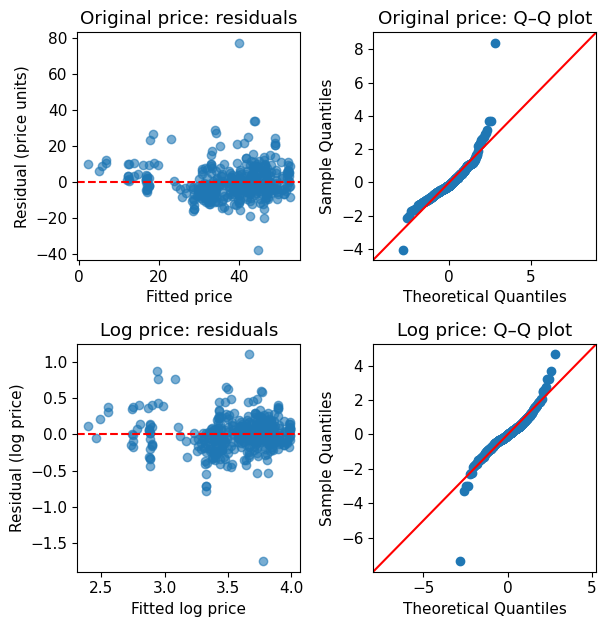

In [38]:
plot_models = [
    (
        "Original price",
        result_multiple,
        "Fitted price",
        "Residual (price units)"
    ),
    (
        "Log price",
        result_log_price,
        "Fitted log price",
        "Residual (log price)"
    )
]

with plt.rc_context({"font.size": 11}):
    fig, axes = plt.subplots(2, 2, figsize=(6.2, 6.4))

    for i, (label, model, x_label, y_label) in enumerate(plot_models):
        axes[i, 0].scatter(
            model.fittedvalues,
            model.resid,
            alpha=0.6
        )

        axes[i, 0].axhline(0, color="red", linestyle="--")
        axes[i, 0].set_title(f"{label}: residuals")
        axes[i, 0].set_xlabel(x_label)
        axes[i, 0].set_ylabel(y_label)

        sm.qqplot(
            model.resid,
            fit=True,
            line="45",
            ax=axes[i, 1]
        )

        axes[i, 1].set_title(f"{label}: Q–Q plot")

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "figure3_diagnostics.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        OUTPUT_DIR / "figure3_diagnostics.pdf",
        bbox_inches="tight"
    )

    plt.show()

In [39]:
#Location groups: one ID per recorded coordinate pair
df["location_id"] = df.groupby(["X5 latitude", "X6 longitude"]).ngroup()

#Are residuals at the same location more similar than residuals overall
res = pd.DataFrame({"loc": df["location_id"], "r": result_log_price.resid})
multi = res[res.groupby("loc")["r"].transform("size") > 1]   # locations with 2+  sales only
within_var = ((multi["r"] - multi.groupby("loc")["r"].transform("mean"))**2).sum() \
             / (len(multi) - multi["loc"].nunique())
print("Overall residual variance:", round(res["r"].var(), 4))
print("Pooled within-location residual variance:", round(within_var, 4))
print("Ratio:", round(within_var / res["r"].var(), 2))

Overall residual variance: 0.0564
Pooled within-location residual variance: 0.0133
Ratio: 0.24


In [40]:
cl = {"groups": df["location_id"]}
result_log_price_simple_cl = model_log_price_simple.fit(cov_type="cluster", cov_kwds=cl, use_t=True)
result_log_price_cl = model_log_price.fit(cov_type="cluster", cov_kwds=cl, use_t=True)

for name, m in {"Model 1 (clustered)": result_log_price_simple_cl,
                "Model 2 (clustered)": result_log_price_cl}.items():
    b = m.params[distance_name]
    lo, hi = m.conf_int().loc[distance_name]
    print(name, "per 100 m (%):",
          [round(100*(np.exp(100*v) - 1), 2) for v in (b, lo, hi)],
          "p =", m.pvalues[distance_name])

Model 1 (clustered) per 100 m (%): [np.float64(-2.31), np.float64(-2.55), np.float64(-2.08)] p = 4.860859207338598e-52
Model 2 (clustered) per 100 m (%): [np.float64(-1.84), np.float64(-2.12), np.float64(-1.56)] p = 1.681797394424156e-29


In [41]:
q1, q3 = df[distance_name].quantile([0.25, 0.75])
b = result_log_price_cl.params[distance_name]
lo, hi = result_log_price_cl.conf_int().loc[distance_name]
gap = q3 - q1
print(f"Q1 = {q1:.0f} m, Q3 = {q3:.0f} m, gap = {gap:.0f} m")
print("Predicted % difference (Q3 vs Q1), with clustered CI:",
      [round(100*(np.exp(gap*v) - 1), 1) for v in (b, lo, hi)])

Q1 = 289 m, Q3 = 1454 m, gap = 1165 m
Predicted % difference (Q3 vs Q1), with clustered CI: [np.float64(-19.5), np.float64(-22.1), np.float64(-16.8)]


In [42]:
X_logd = sm.add_constant(pd.DataFrame({
    "log_distance": np.log(df[distance_name]),
    "age": df["X2 house age"],
    "stores": df["X4 number of convenience stores"]}))
result_loglog = sm.OLS(log_price, X_logd).fit()
print("Adj R², log price ~ distance (m) + controls:", round(result_log_price.rsquared_adj, 3))
print("Adj R², log price ~ log distance + controls:", round(result_loglog.rsquared_adj, 3))

Adj R², log price ~ distance (m) + controls: 0.631
Adj R², log price ~ log distance + controls: 0.611


In [43]:
#Log-scale results used in the report
terms = {distance_name: ("MRT distance(+100 m)", 100),
         "X2 house age": ("House age(+1 year)", 1),
         "X4 number of convenience stores": ("Convenience stores(+1)", 1)}
rows = []
for name, m in {"Model 1": result_log_price_simple, "Model 2": result_log_price}.items():
    
    for var, (label, k) in terms.items():
        
        if var in m.params.index:
            lo, hi = m.conf_int().loc[var]
            rows.append([name, label, round(k * m.params[var], 4), round(k * lo, 4), round(k * hi, 4)])
            
display(pd.DataFrame(rows, columns=["Model", "Term", "Coefficient", "CI lower", "CI upper"]))

print("Relative reduction in distance coefficient:",
      round(1 - result_log_price.params[distance_name] / result_log_price_simple.params[distance_name], 3))

lo, hi = result_log_price_cl.conf_int().loc[distance_name]

print("Model 2, clustered CI per 100 m:", round(100 * lo, 4), round(100 * hi, 4))
print("Model 2 without No. 271, per 100 m:", round(100 * result_log_price_without271.params[distance_name], 4))


,Model,Term,Coefficient,CI lower,CI upper
0,Model 1,MRT distance(+100 m),-0.0234,-0.0254,-0.0214
1,Model 2,MRT distance(+100 m),-0.0186,-0.0209,-0.0163
2,Model 2,House age(+1 year),-0.0064,-0.0084,-0.0044
3,Model 2,Convenience stores(+1),0.0330,0.0231,0.0428


Relative reduction in distance coefficient: 0.205
Model 2, clustered CI per 100 m: -0.0215 -0.0158
Model 2 without No. 271, per 100 m: -0.0182


## I. Final checks


In [44]:
print("Main dataset:", df.shape)
print("Unique transaction numbers:", df["No"].nunique())

print("Distance variable:", type(distance).__name__)
print("Price variable:", type(price).__name__)

print(
    "Final model sample sizes:",
    int(result_log_price_simple.nobs),
    int(result_log_price.nobs)
)

print(
    "Sample excluding No. 271:",
    int(result_log_price_without271.nobs)
)

print("Coordinate groups:", len(location_counts))

Main dataset: (414, 9)
Unique transaction numbers: 414
Distance variable: Series
Price variable: Series
Final model sample sizes: 414 414
Sample excluding No. 271: 413
Coordinate groups: 259
